Usual package boilerplate

In [1]:
using Pkg
pkg"activate .; instantiate; precompile"
using CSV, Plots, JSON, BenchmarkTools, Parameters, PerlaTonettiWaugh, DataFrames
gr(fmt = :png)

  Updating registry at `~/.julia/registries/General`
  Updating git-repo `https://github.com/JuliaRegistries/General.git`
Precompiling project...


Plots.GRBackend()

We can instantiate our parameters and settings

In [2]:
parameters = parameter_defaults();
settings = settings_defaults();

We can inspect the experiment

In [3]:
@show parameters.d_0, parameters.d_T;

(parameters.d_0, parameters.d_T) = (3.0426, 2.8383400000000005)


And

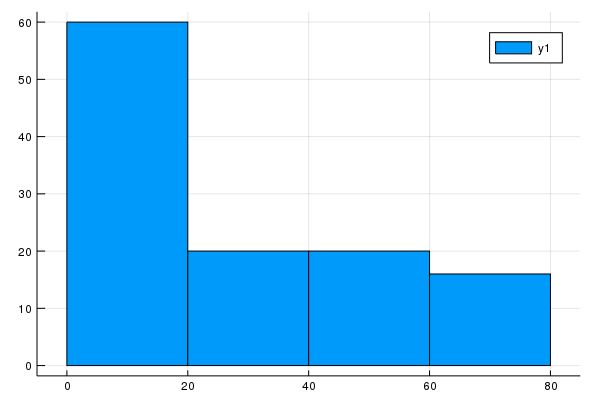

In [4]:
histogram(settings.tstops)

As we can see, the `tstops` are front-loaded. 

Let's run the experiment.

In [5]:
sol = @time solve_transition_FP(parameters, settings);
solved = sol.dynamics_output.results;

┌ Warning: The isoutofdomain argument is ignored by Sundials.IDA{:Dense}(0, 0, 0, 0, 5, 7, 0.33, 3, 10, 0.0033, 5, 4, 10, 100, true, false).
└ @ DiffEqBase /Users/arnavsood/.julia/packages/DiffEqBase/EFqMn/src/utils.jl:60
┌ Warning: Please see http://docs.juliadiffeq.org/latest/basics/compatibility_chart.html
└ @ DiffEqBase /Users/arnavsood/.julia/packages/DiffEqBase/EFqMn/src/utils.jl:67
┌ Warning: The isoutofdomain argument is ignored by Sundials.IDA{:Dense}(0, 0, 0, 0, 5, 7, 0.33, 3, 10, 0.0033, 5, 4, 10, 100, true, false).
└ @ DiffEqBase /Users/arnavsood/.julia/packages/DiffEqBase/EFqMn/src/utils.jl:60
┌ Warning: Please see http://docs.juliadiffeq.org/latest/basics/compatibility_chart.html
└ @ DiffEqBase /Users/arnavsood/.julia/packages/DiffEqBase/EFqMn/src/utils.jl:67
┌ Warning: The isoutofdomain argument is ignored by Sundials.IDA{:Dense}(0, 0, 0, 0, 5, 7, 0.33, 3, 10, 0.0033, 5, 4, 10, 100, true, false).
└ @ DiffEqBase /Users/arnavsood/.julia/packages/DiffEqBase/EFqMn/src/utils.

362.069069 seconds (972.44 M allocations: 740.231 GiB, 33.68% gc time)


## Plots

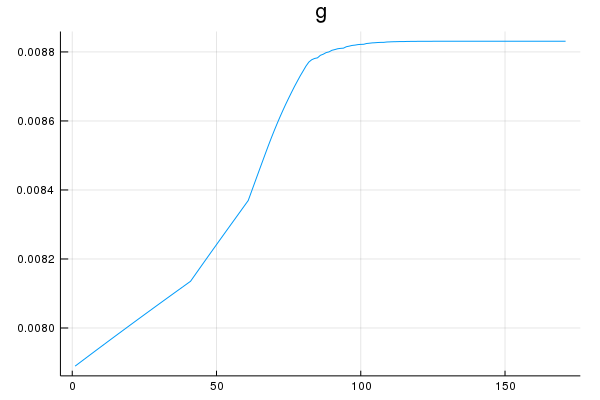

In [6]:
plot(solved.g, legend = false, title = "g")

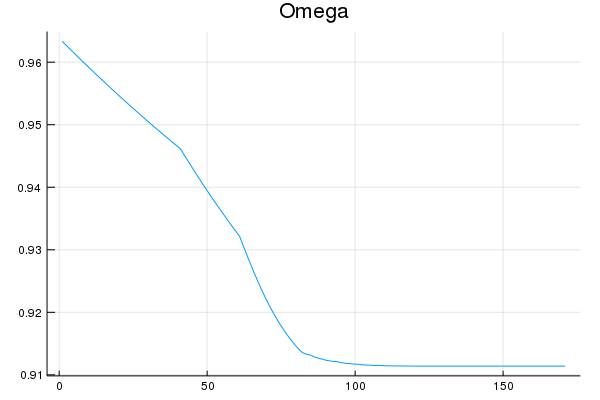

In [7]:
plot(solved.Ω, legend = false, title = "Omega")

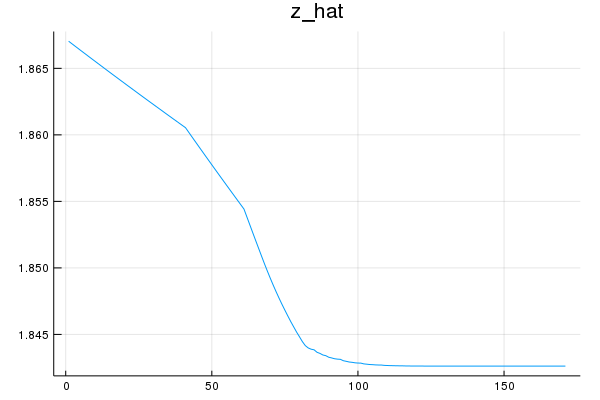

In [8]:
plot(solved.z_hat, legend = false, title = "z_hat")

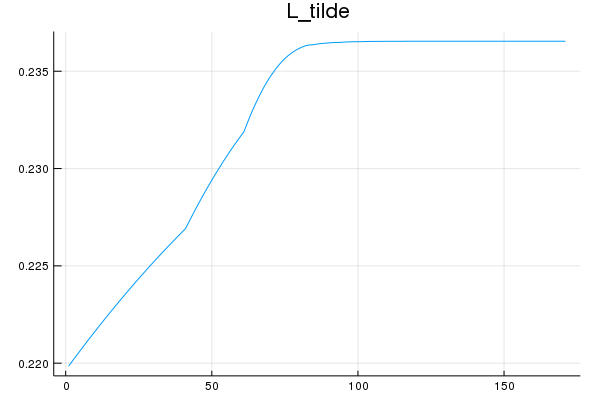

In [9]:
plot(solved.L_tilde, legend = false, title = "L_tilde")